<a href="https://colab.research.google.com/github/lilydeller/Math344-Project/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part A

Clone our project repository and import functions from Milestone 2.

In [ ]:
import subprocess
import sys
from pathlib import Path

USER = "lilydeller"
REPO = "Math344-Project"

if Path(REPO).exists():
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO], check=True
    )

sys.path.insert(0, f"{REPO}/src")

from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

Download the movie dataset and create our training data, testing data, fitting data, and validation data.

In [ ]:
from io import BytesIO
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

ML_DATASET = Path("ml-100k")

if not ML_DATASET.exists():
    url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
    response = requests.get(url)

    ZipFile(BytesIO(response.content)).extractall()

movie_ratings = pd.read_csv(
    ML_DATASET / "u.data", sep="\t", names=["user", "item", "rating", "time"]
)

train, test = split_ratings(movie_ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit: ", len(fit), " validation: ", len(val), " test: ", len(test))

fit:  81200  validation:  8832  test:  9968


# Part B

Calculate the root mean squared error for the prediction matrix with predictions clipped between 1 to 5 stars.

In [ ]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

# Part C

Create a baseline matrix to score against.

In [ ]:
def baseline_matrix(R):
    """Full matrix: overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE: ", round(baseline_val_rmse, 4))

Baseline validation RMSE:  0.9731


# Part D

In [ ]:
def rank_k(U, s, Vt, k):
    """Build a rank-k matrix from an already computed SVD."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

#Part E: Model 1

Fills the missing entries in the fitting data with the movie's average rating so an SVD can be computed on it.

In [ ]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])
F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

#Part F: Model 2

Gets the rating's difference between the actual (R fit) and the baseline ratings (B fit), marking a difference of 0 for where a user didn't leave a rating. Then, using an SVD, forms a low-rank approx on these differences.

In [ ]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

#Part G

This code compares model 1 and 2 using the validation data. For each rank it creates a prediction matrix for each model and calculates the validation RMSE. Model 2 adds the baseline back to obtain star ratings. The code selects and prints the rank with the lowest validation RMSE for each model. It uses only validation data to choose the ranks, keeping the test data reserved for the final evaluation.

In [ ]:
ks=[1, 2,3,5,10,15,20,30, 50,100]
val_err1,val_err2=[],[]

for k in ks:
  P1 = rank_k(U1,s1,Vt1,k)
  P2 = rank_k(U2,s2,Vt2,k)+ B_fit
  val_err1.append(score_at(P1, val_u, val_i, val_truth))
  val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1=ks[int(np.argmin(val_err1))]
best_k2=ks[int(np.argmin(val_err2))]
print("Best Model 1 k: " , best_k1,"validation RMSE: " ,min(val_err1))
print("Best Model 2 k: " , best_k2,"validation RMSE: ",min(val_err2))

Best Model 1 k:  15 validation RMSE:  0.9934477108911378
Best Model 2 k:  15 validation RMSE:  0.9492241710885614


This code plots the validation RMSE for both models against rank, using a logarithmic scale on the horizontal axis. It adds a horizontal line showing the baseline’s validation RMSE so we can compare the models with the baseline. Lower values indicate better predictions, and points below the baseline line show an improvement over the baseline. Finally, the code labels the graph, saves it as an image, and displays it.

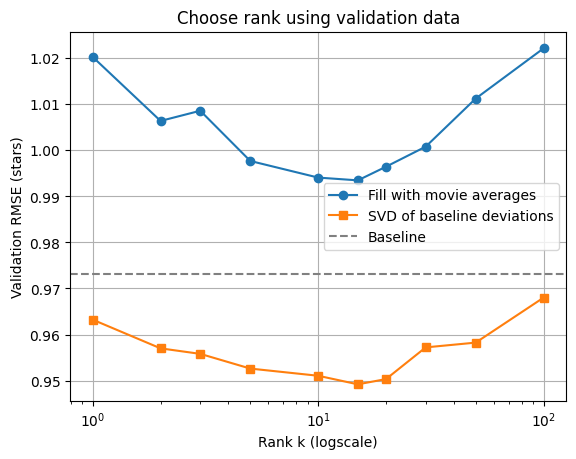

In [ ]:
plt.semilogx(ks,val_err1,"o-",label="Fill with movie averages")
plt.semilogx(ks, val_err2, "s-",label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray",linestyle="--", label="Baseline")
plt.xlabel("Rank k (logscale)")
plt.ylabel("Validation RMSE (stars)")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png",dpi=150)
plt.show()

# Part H

In [ ]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)

    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)

    return L + B

In [ ]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


The iterative SVD model repeatedly improves its predictions for missing movie ratings by using patterns found in the existing ratings. Unlike Model 2, which initially fills missing deviations with zeros, this model updates those missing values after each iteration using the low-rank approximation. Throughout this process, the actual training ratings remain unchanged. I tested ranks of 2, 5, 10, and 20, running each model for 10 iterations. Rank 2 produced the lowest validation RMSE of 0.9431, making it the best-performing rank for Model 3. This means that, among the ranks tested, rank 2 provided the most accurate predictions on the validation data.

# Part I


In [ ]:
R_train = to_matrix(train)

test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = "iterative SVD"

elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = "baseline plus low-rank deviations"

else:
    known_train = ~np.isnan(R_train)

    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)

    has_train = n_item_train > 0

    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] /
        n_item_train[has_train]
    )

    F_train = np.where(
        known_train, R_train, means_train[None, :]
    )

    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)

    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)

print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


In this section, I retrained the selected recommendation model using all available training data, including the previous validation data. I compared the validation RMSE values from the three models to determine which performed best. The selected model was then evaluated against the original hidden test set. I also calculated the baseline test RMSE to compare its performance against the more advanced model. The test results provide an estimate of how well the recommendation system predicts ratings it has not previously seen.

# Part J

The first 4 lines load the movie IDs and the titles. In the file, fields are separated with |. usecols=[0, 1] uses the first 2 columns of the u.item file, which are titled item and title on the 5th line. Then, the user id starts at 1, with the user row being 1 less. R_train[user_row] then gets that user's training ratings, where missing ratings are stored as NaN. unrated contains the indices of the NaN ratings, which are the columns eligible for recommendations.

Then, the code gets the predicted ratings for those movies for that user, with np.clip limiting them to a range of 1 to 5 stars. Top then contains the five highest-scoring unrated movies. After that, for each column (movie) in the top 5 highest rated predictions, the loop finds the movie using its id, which is 1 higher than its column index, and then makes a series containing the title, which is then selected by .iloc[0]. The title variable is then set to that title that was pulled. After that, the title and its predited rating, rounded to 2 decimal places, are printed for each unrated movie in the loop.

In [ ]:
item_info = pd.read_csv(
    "ml-100k/u.item", sep="|", header=None, usecols=[0, 1],
    encoding="latin-1"
)
item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
  title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
  print(title, "predicted rating:", round(predicted_scores[col], 2))

Pulp Fiction (1994) predicted rating: 5.0
Saint of Fort Washington, The (1993) predicted rating: 5.0
Great Day in Harlem, A (1994) predicted rating: 5.0
Santa with Muscles (1996) predicted rating: 5.0
Aiqing wansui (1994) predicted rating: 5.0
